In [ ]:
import os
import numpy as np
import cv2

from matplotlib import pyplot as plt
import matplotlib 

# Local descriptors
from skimage.feature import hog
from skimage import  exposure
from skimage import feature

from time import time
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_score, recall_score
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import MinMaxScaler


import warnings
warnings.filterwarnings("ignore")

## Fase 1. Definición de funciones y carga de datos


lbphist Definido un número de celdas, calcula el histograma LBP de cada una, concatenando los histogramas resultantes

GetHOG y GetLPB obtención de descriptores locales

GetPredictions y GetPredictionsandProbs obtienen las etiquetas o probabilidades para un conjunto de test utilizando clasificadores SVM

LoadDataset Carga conjunto de datos. Se proporciona la carpeta, a través de la variable folder, donde cada subcarpeta se corresponde con una clase. Cada clase contiene muestras en forma de imágenes jpg, todas del mismo tamaño 


In [3]:
# Número de valores posibles del LBP con P=8 vecinos según el método
LBP_NBINS = {'default': 2**8, 'ror': 2**8, 'uniform': 8 + 2, 'nri_uniform': 8*7 + 3, 'var': 8 + 2}

def lbphist(gray, ncellsx, ncellsy, width, height, type):
    #Rejilla de histogramas
    pxpercellx = int(width/ncellsx)
    pxpercelly = int(height/ncellsy)

    # Rejillas de igual tamaño y centradas en la imagen de entrada
    ofx = int((width - int(pxpercellx)*ncellsx)/2)
    ofy = int((height - int(pxpercelly)*ncellsy)/2)
   
    #Obtiene histograma LBP para cada celda
    LBPu_hist = []
    for i in range(0,ncellsy):
        for j in range(0,ncellsx):
            # Extrae celda
            roi=gray[ofy+i*pxpercelly:ofy+(i+1)*pxpercelly,ofx+j*pxpercellx:ofx+(j+1)*pxpercellx]
            # Obtiene imagen LBP
            lbpimg = feature.local_binary_pattern(roi, 8, 1,method=type)
            
            #Obtiene histograma
            # CORREGIDO: el número de bins debe ser FIJO para que todas las imágenes
            # tengan un vector de la misma longitud. Antes se usaba lbpimg.max()+1,
            # que cambia de una celda/imagen a otra y provocaba el error
            # "inhomogeneous shape" al convertir a numpy array.
            n_bins = LBP_NBINS[type]            
            #feath, bins = np.histogram(lbpimg.ravel(), normed=True, bins=n_bins, range=(0,n_bins))
            #feath, bins = np.histogram(lbpimg, normed=False, bins=n_bins, range=(0,n_bins)) #normed deprecated
            feath, bins = np.histogram(lbpimg, density=False, bins=n_bins, range=(0,n_bins))
            
            # Concatena con celdas previas
            LBPu_hist= np.concatenate([LBPu_hist , feath])
            
    return LBPu_hist

def GetHOG(X, ncellsx, ncellsy, width, height):
    Xhog = []
    for i in range(len(X)):
        #Recompone imagen
        gray = X[i].reshape(height, width)
        
        # HOG            
        feat_hog, hog_image = hog(gray, orientations=8, pixels_per_cell=(height/ncellsy, width/ncellsx),
                    cells_per_block=(1, 1), visualize=True, block_norm='L1')   #multichannel=False,  elimindo en versiones recientes
        Xhog.append(feat_hog)
            
    return Xhog
        
def GetLBP(X, ncellsx, ncellsy, width, height, lbptype):
    Xlbp = []
    for i in range(len(X)):
        #Recompone imagen
        # CORREGIDO: LBP sobre imagen entera (uint8), no float
        gray = X[i].reshape(height, width).astype(np.uint8)
        
        # LBP
        feat_lbp = lbphist(gray, ncellsx, ncellsy, width, height, lbptype) 
        Xlbp.append(feat_lbp)
                
    return Xlbp

def GetPredictions(X_train, X_test, y_train, y_test):
    
    print("SVM Normalization...")
    scaler = MinMaxScaler()
    train_X = scaler.fit_transform(X_train)
    test_X = scaler.transform(X_test)

    print("SVM training...")
    t0 = time()
    parameters = {'C': [1e3, 5e3],
                  'gamma': [0.0001, 0.0005, 0.001, 0.005, 0.01],}
    # Grid searach across parameter range
    clf = GridSearchCV(
        SVC(kernel='rbf', class_weight='balanced'), parameters, cv=3, n_jobs=-1
    )
    clf = clf.fit(train_X, y_train)
    print("done in %0.3fs" % (time() - t0))
    print("Best estimator found by grid search:")
    print(clf.best_estimator_)

    print("Predicting")
    t0 = time()
    # test labels
    y_pred = clf.predict(test_X)
   
    print("done in %0.3fs" % (time() - t0))
    
    return y_pred, y_test

def GetPredictionsandProbs(X_train, X_test, y_train, y_test):
    
    print("SVM Normalization...")
    scaler = MinMaxScaler()
    train_X = scaler.fit_transform(X_train)
    test_X = scaler.transform(X_test)

    print("SVM training...")
    t0 = time()
    parameters = {'C': [1e3, 5e3],
                  'gamma': [0.0001, 0.0005, 0.001, 0.005, 0.01],}
    # Grid search across parameter range
    clf = GridSearchCV(
        SVC(kernel='rbf', class_weight='balanced'), parameters, cv=3, n_jobs=-1
    )
    clf = clf.fit(train_X, y_train)
    print("done in %0.3fs" % (time() - t0))
    print("Best estimator found by grid search:")
    print(clf.best_estimator_)

    print("Predicting")
    t0 = time()
    # test labels
    y_pred = clf.predict(test_X)
    
    # train and test class probabilities
    # CORREGIDO: las probabilidades de entrenamiento se obtienen con validación
    # cruzada (cross_val_predict). Si se calculan con el mismo modelo que se
    # entrenó con esas muestras, salen casi perfectas y el clasificador del
    # stacking aprende a fiarse de ellas: sobreajuste.
    best = SVC(kernel='rbf', class_weight='balanced', probability=True,
               C=clf.best_params_['C'], gamma=clf.best_params_['gamma'])
    ytrain_prob = cross_val_predict(best, train_X, y_train, cv=3, method='predict_proba', n_jobs=-1)
    best.fit(train_X, y_train)
    ytest_prob = best.predict_proba(test_X)
    
    print("done in %0.3fs" % (time() - t0))
    
    return y_pred, y_test, ytrain_prob, ytest_prob


def LoadDataset(folder, ext):
    # Contador de número de clases del conjunto
    nclasses = 0
    # Contador de muestras por clase
    nperclass = []
    # Etiqueta de cada clase (nombre de la subcarpeta)
    classlabels = []
    # Inicializa estructuras de datos y sus correpondientes etiquetas
    X = []
    Y = []
   
    # Asume que en la ruta indicada hay una subcarpeta por clase
    for class_name in os.listdir(folder):
        # Cada subcarpeta implica una clase más
        nclasses += 1
        # Inicialmente esta clase no tiene muestras
        nsamples = 0    

        # Compone la ruta
        class_folder = os.path.join(folder, class_name)
        for file_name in os.listdir(class_folder):
            # Imágenes en formato ext
            if file_name.endswith(ext):
                # Lee la imagen
                image = cv2.imread (os.path.join(class_folder, file_name))

                # Lugar para aplicar un RoI sobre la imagen de entrada
                # Ejemplo para la mitad superior
                # image = image[0:int(height/2),:]

                # Extrae tamaños
                height, width, depth = image.shape
                # Convierte  grises
                gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
                # Añade a X, previa conversión en vector
                X.append(gray.reshape(height*width))

                # Añade etiqueta numérica de la muestra
                Y.append(nclasses-1)

                #Incrementa el número de muestras
                nsamples += 1
        
        nperclass.append(nsamples)
        classlabels.append(class_name)
    
    return X, Y, nsamples, class_name, nperclass, classlabels, width, height



Carga de imágenes con el dataset original, en este caso decidimos usar train

Loading dataset
Dataset info:
# samples: 28709
# featues: 2304
# classes: 7
classes ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
samples per class 3995, 436, 4097, 7215, 4965, 4830, 3171


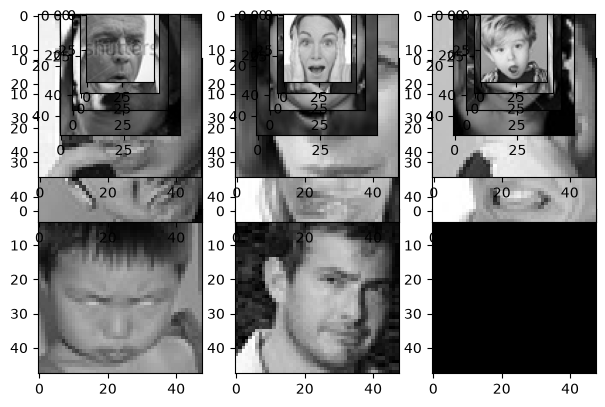

In [ ]:
#MODIFICAR INDICANDO RUTA EN TU EQUIPO TRAS DESCAGAR DATOS DEL CAMPUS. EVITAR TILDES
folder = r"C:\UNI\4 Curso\VC\repo\practicasVC\P5\dataset_emociones\train" #RUTA EJEMPLO, MODIFICAR

print('Loading dataset')
X, Y, nsamples, class_name, nperclass, classlabels, width, height = LoadDataset(folder,'.jpg')

#Convierte a numpy array X e Y
X = np.array(X,dtype='float32')
Y = np.array(Y,dtype='float64')

# Obtiene número de muestras y características
n_samples , n_features = X.shape
# Obtiene nombres de las clases
class_names = np.array(classlabels)
n_classes = class_names.shape[0]

print("Dataset info:")
print("# samples: %d" % n_samples)
print("# featues: %d" % n_features)
print("# classes: %d" % n_classes)
print("classes %s" % classlabels)
print("samples per class %s" % str(nperclass)[1:-1] )
        
#Muestra primeras muestras de cada clase                                                   
# Valor de resolución por defecto de matplotlib
dpi = matplotlib.rcParams['figure.dpi']
# Imágenes de muestra de cada clase
nims2show = 3
 
for nc in range(n_classes):
    nimgs = 0
    i = 0
    while i < nims2show and nimgs < n_samples:
        #Es muestra de la clase que interesa
        if Y[nimgs] == nc:
            gray = X[nimgs].reshape(height, width)
            #Con la primera define configuración
            if i == 0 and nc == 0:                    
                figsize = 15*width / float(dpi), 15*height / float(dpi)
                fig = plt.figure(figsize=figsize)                
                        
            fig.add_subplot(nc + 1,nims2show, i + 1)
            plt.imshow(gray, cmap='gray', vmin=0, vmax=255) 

            i += 1 
        nimgs += 1
    
plt.show()

In [5]:
# NUEVO: submuestreo opcional del dataset
# FER2013 tiene ~28.700 imágenes. Con SVM RBF + GridSearch y 5 folds el
# experimento completo tardaría muchísimas horas. Para iterar rápido se toma
# un máximo de MAX_PER_CLASS muestras por clase (las clases pequeñas, como
# 'disgust', se quedan con todas las que tienen).
# Pon MAX_PER_CLASS = None para usar el dataset completo.
MAX_PER_CLASS = 500

if MAX_PER_CLASS is not None:
    rng = np.random.RandomState(0)
    idx = []
    for c in range(n_classes):
        ic = np.where(Y == c)[0]
        idx.extend(rng.choice(ic, min(MAX_PER_CLASS, len(ic)), replace=False))
    idx = np.array(sorted(idx))
    X, Y = X[idx], Y[idx]
    n_samples = X.shape[0]

print("Muestras usadas: %d" % n_samples)
print("Por clase:", {class_names[c]: int((Y == c).sum()) for c in range(n_classes)})


Muestras usadas: 3436
Por clase: {np.str_('angry'): 500, np.str_('disgust'): 436, np.str_('fear'): 500, np.str_('happy'): 500, np.str_('neutral'): 500, np.str_('sad'): 500, np.str_('surprise'): 500}


In [6]:
#Obtiene HOG y LBP para determinada configuración de celdas
#Pueden probarse otras configuraciones
Xhog4x4 = GetHOG(X, 4, 4, width, height)
Xlbp3x3 = GetLBP(X, 3, 3, width, height, "nri_uniform") #uniform a secas es también rotation invariant
    
#Convierte a numpy array X e Y
Xhog4x4 = np.array(Xhog4x4,dtype='float32')
Xlbp3x3 = np.array(Xlbp3x3,dtype='float32')

## Fase 2. Diseña conjunto experimental k-fold

Divide los datos k veces en conjunto de entrenamiento y test

In [7]:
# StratifiedKFold
# Define el número de subconjuntos a considerar
kfold = 5
skf = StratifiedKFold(n_splits=kfold, random_state=4, shuffle=True)
#Distribución de muestras por fold
fold = 1
for train_index, test_index in skf.split(X, Y):
    #print("TRAIN:", train_index, "TEST:", test_index)
    print("Fold %d" % fold)
    print("# samples in training set %d" % train_index.shape[0])
    print("# samples in test set %d" % test_index.shape[0])
    fold += 1

Fold 1
# samples in training set 2748
# samples in test set 688
Fold 2
# samples in training set 2749
# samples in test set 687
Fold 3
# samples in training set 2749
# samples in test set 687
Fold 4
# samples in training set 2749
# samples in test set 687
Fold 5
# samples in training set 2749
# samples in test set 687



Cálculo en primer término de PCA (95% de la varianza) de las muestras de entrenamiento. Posteriormente:
- Clasifica con píxeles como características y KNN
- Clasifica con componentes PCA como características con KNN
- Clasifica con componentes PCA como características con SVM
- Clasifica con LBP como características con SVM
- Clasifica con HOG como características con SVM
- Stacking de los tres últimos

In [8]:
# Compute PCA on the training subset for n_comp components
print("+++++++++++++++++++++++++++++++++++++++++++\n")
n_comp = 150

# KNN parámetros
knn = 5

#Valores de precision y recall
precs_px_knn, recs_px_knn = [], []
precs_pca_knn, recs_pca_knn = [], []
precs_pca_svm, recs_pca_svm = [], []
precs_hog_svm, recs_hog_svm = [], []
precs_lbp_svm, recs_lbp_svm = [], []
precs_stk_svm, recs_stk_svm = [], []

# Recorre folds
fold = 1
while fold <= kfold:
    accs, precs, recs = [], [], []
    for train_index, test_index in skf.split(X, Y):
        #print("TRAIN:", train_index, "TEST:", test_index)
        print("***\nFold %d" % fold)
        #División de muestras de entreno y test
        X_train, X_test = X[train_index], X[test_index]
        #Etiquetas de las muestras
        y_train, y_test = Y[train_index], Y[test_index]
        #Muestras HOG y LBP de entreno y test
        Xhog4x4_train, Xhog4x4_test = Xhog4x4[train_index], Xhog4x4[test_index]
        Xlbp3x3_train, Xlbp3x3_test = Xlbp3x3[train_index], Xlbp3x3[test_index]
        
        #####################################
        # Píxeles y KNN
        print("\nPXL+KNN")
        t0 = time()
        # k = 5 
        model_px = KNeighborsClassifier(n_neighbors = knn) 

        # fdtraining of model 
        model_px.fit(X_train, y_train) 
        print("done in %0.3fs" % (time() - t0))

        print("Predicting...")
        t0 = time()
        y_pred=model_px.predict(X_test)

        print("done in %0.3fs" % (time() - t0))
        
        print("Classification results:")
        print(classification_report(y_test, y_pred, target_names=class_names))       
        
        precs_px_knn.append(precision_score(y_test, y_pred, average='macro'))
        recs_px_knn.append(recall_score(y_test, y_pred, average='macro'))
    
        # Confusion matriz just for first fold
        if fold == 1:
            print("Confussion matrix:")
            print(confusion_matrix(y_test, y_pred, labels=range(n_classes)))
        
        ##############################################
        print("PCA computation for .95 of the variance from %d faces..."
        % (X_train.shape[0]))
        t0 = time()
        pca_95 = PCA(.95).fit(X_train)
        print("done in %0.3fs" % (time() - t0))
        print("%d components selected" % (pca_95.n_components_ ))

        eigenfaces_95 = pca_95.components_.reshape((pca_95.n_components_ , height, width))

        print("Projecting training and test on the eigenfaces orthonormal basis")
        t0 = time()
        X_train_pca_95 = pca_95.transform(X_train)
        X_test_pca_95 = pca_95.transform(X_test)
        print("done in %0.3fs" % (time() - t0))
        
        #####################################
        # PCA y KNN
        print("\nPCA+KNN")
        print("KNN (k=%d) classifier based on %d PCA components..." % (knn, pca_95.n_components_) ) 
        t0 = time()
        model_pca_95 = KNeighborsClassifier(n_neighbors = knn) 

        # fdtraining of model 
        model_pca_95.fit(X_train_pca_95, y_train) 
        print("done in %0.3fs" % (time() - t0))

        print("Predicting...")
        t0 = time()
        y_pred=model_pca_95.predict(X_test_pca_95)

        print("done in %0.3fs" % (time() - t0))

        print("\nMetrics")
        print(classification_report(y_test, y_pred, target_names=class_names))
        precs_pca_knn.append(precision_score(y_test, y_pred, average='macro'))
        recs_pca_knn.append(recall_score(y_test, y_pred, average='macro'))
        
        if fold == 1:
            print("Confusion matrix:")
            print(confusion_matrix(y_test, y_pred, labels=range(n_classes)))
        
        print("+++++++++++++++++++++++++++++++++++++++++++\n")
        #####################################
        # PCA y SVM
        print("\nPCA+SVM")        
        y_pred, y_test = GetPredictions(X_train_pca_95, X_test_pca_95,y_train, y_test)
        print("\nMetrics")
        print(classification_report(y_test, y_pred, target_names=class_names))
        precs_pca_svm.append(precision_score(y_test, y_pred, average='macro'))
        recs_pca_svm.append(recall_score(y_test, y_pred, average='macro'))

        if fold == 1:
            print("Confusion matrix:")
            print(confusion_matrix(y_test, y_pred, labels=range(n_classes)))
            
        #####################################
        # HOG y SVM
        print("\nHOG+SVM")
        y_pred, y_test = GetPredictions(Xhog4x4_train, Xhog4x4_test,y_train, y_test)
        print("\nHOG Metrics")
        precs_hog_svm.append(precision_score(y_test, y_pred, average='macro'))
        recs_hog_svm.append(recall_score(y_test, y_pred, average='macro'))
        print(classification_report(y_test, y_pred, target_names=class_names))
        if fold == 1:
            print("Confusion matrix:")
            print(confusion_matrix(y_test, y_pred, labels=range(n_classes)))        
        
        #####################################
        # LBP y SVM
        print("\nLBP+SVM")
        y_pred, y_test = GetPredictions(Xlbp3x3_train, Xlbp3x3_test,y_train, y_test)
        print("\nLBP Metrics")
        precs_lbp_svm.append(precision_score(y_test, y_pred, average='macro'))
        recs_lbp_svm.append(recall_score(y_test, y_pred, average='macro'))
        print(classification_report(y_test, y_pred, target_names=class_names))
        if fold == 1:
            print("Confusion matrix:")
            print(confusion_matrix(y_test, y_pred, labels=range(n_classes)))


        #####################################
        #Ensemble
        print("\nEnsemble/Stacking")
        #Obtiene también probs
        y_pred, y_test, pca95_train_prob, pca95_test_prob = GetPredictionsandProbs(X_train_pca_95, X_test_pca_95,y_train, y_test)
        y_pred, y_test, hog_train_prob, hog_test_prob = GetPredictionsandProbs(Xhog4x4_train, Xhog4x4_test,y_train, y_test)
        y_pred, y_test, lbp_train_prob, lbp_test_prob = GetPredictionsandProbs(Xlbp3x3_train, Xlbp3x3_test,y_train, y_test)
        # Score level fusion, using reported probabilities
        # CORREGIDO: con 7 clases hay que usar las probabilidades de TODAS las
        # clases (antes solo se tomaba la columna 1, que en un problema binario
        # bastaba). Cada muestra queda descrita por 3 x n_classes probabilidades.
        X_train_stk = np.hstack((pca95_train_prob, hog_train_prob, lbp_train_prob))
        X_test_stk = np.hstack((pca95_test_prob, hog_test_prob, lbp_test_prob))
        y_pred, y_test = GetPredictions(X_train_stk, X_test_stk, y_train, y_test)
            
        print("\nEnsemble/Stacking Metrics")
        precs_stk_svm.append(precision_score(y_test, y_pred, average='macro'))
        recs_stk_svm.append(recall_score(y_test, y_pred, average='macro'))
        print(classification_report(y_test, y_pred, target_names=class_names))
        print("Confusion matrix:")
        print(confusion_matrix(y_test, y_pred, labels=range(n_classes)))
        
        fold += 1

print("\n********K-FOLD SUMMARY (macro average)*********")
print("PX+KNN Mean Precision:  %0.3f, Mean Recall:  %0.3f" % ( np.mean(precs_px_knn) , np.mean(recs_px_knn) ))
print("PCA+KNN Mean Precision:  %0.3f, Mean Recall:  %0.3f" % ( np.mean(precs_pca_knn) , np.mean(recs_pca_knn) )) 
print("PCA+SVM Mean Precision:  %0.3f, Mean Recall:  %0.3f" % ( np.mean(precs_pca_svm) , np.mean(recs_pca_svm) )) 
print("HOG+SVM Mean Precision:  %0.3f, Mean Recall:  %0.3f" % ( np.mean(precs_hog_svm) , np.mean(recs_hog_svm) )) 
print("LBP+SVM Mean Precision:  %0.3f, Mean Recall:  %0.3f" % ( np.mean(precs_lbp_svm) , np.mean(recs_lbp_svm) )) 
print("Ensemble Mean Precision:  %0.3f, Mean Recall:  %0.3f" % ( np.mean(precs_stk_svm) , np.mean(recs_stk_svm) )) 

    

+++++++++++++++++++++++++++++++++++++++++++

***
Fold 1

PXL+KNN
done in 0.010s
Predicting...
done in 0.229s
Classification results:
              precision    recall  f1-score   support

       angry       0.20      0.27      0.23       100
     disgust       0.27      0.58      0.36        88
        fear       0.18      0.12      0.14       100
       happy       0.16      0.11      0.13       100
     neutral       0.26      0.33      0.29       100
         sad       0.26      0.11      0.15       100
    surprise       0.32      0.18      0.23       100

    accuracy                           0.24       688
   macro avg       0.23      0.24      0.22       688
weighted avg       0.23      0.24      0.22       688

Confussion matrix:
[[27 24  8  9 24  5  3]
 [13 51  4  3 10  2  5]
 [18 18 12 15 21  7  9]
 [25 24  7 11 15  6 12]
 [20 19  3 10 33  7  8]
 [18 30 13 14 13 11  1]
 [13 26 21  5 12  5 18]]
PCA computation for .95 of the variance from 2748 faces...
done in 3.553s
217 comp

## Fase 3. Clasificador final: eigenfaces + SVM

El k-fold anterior sirve para comparar descriptores, pero entrena con un submuestreo y descarta los modelos de cada fold. Aquí se entrena **un único modelo** con **todo** `dataset_emociones/train` (28.709 imágenes) para usarlo en la evaluación y en la demo:

1. **PCA (95 % de la varianza)** → eigenfaces. Cada cara de 48x48 = 2.304 píxeles pasa a unos pocos cientos de coeficientes.
2. **MinMaxScaler** sobre esos coeficientes, igual que en `GetPredictions`.
3. **SVM RBF** con `class_weight='balanced'` (la clase *disgust* tiene muchas menos muestras).

No se repite el GridSearch: se usan los hiperparámetros que eligió en el k-fold para PCA+SVM (`C=1000`, `gamma=0.0001` en 4 de los 5 folds).

El modelo se guarda en `models/eigenfaces_svm.joblib`; si ya existe se carga directamente (poner `REENTRENAR = True` para forzar el entrenamiento). El entrenamiento del SVM con todas las imágenes puede tardar del orden de decenas de minutos.

### 3.1 Entrenamiento (o carga) del modelo final PCA + SVM

In [ ]:
# ===== 3.1.1 Entrenamiento (o carga) del modelo final PCA + SVM =====
import joblib
import os
import cv2
import numpy as np
from time import time
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report

from matplotlib import pyplot as plt
from utils import LoadDataset

folder = r"C:\UNI\4 Curso\VC\repo\practicasVC\P5\dataset_emociones\train" #RUTA EJEMPLO, MODIFICAR
TRAIN_DIR = folder                                              # dataset_emociones/train
TEST_DIR = os.path.join(os.path.dirname(folder), "test")        # dataset_emociones/test
MODELO_PATH = Path("models/eigenfaces_svm.joblib")
REENTRENAR = False

SVM_C, SVM_GAMMA = 1e3, 1e-4

if MODELO_PATH.exists() and not REENTRENAR:
    guardado = joblib.load(MODELO_PATH)
    print(f"Modelo cargado de {MODELO_PATH}")
else:
    # Se recarga train completo: la celda de submuestreo sobrescribió X e Y
    print("Cargando train completo...")
    Xtr, Ytr, _, _, _, clases_tr, w_tr, h_tr = LoadDataset(TRAIN_DIR, '.jpg')
    Xtr, Ytr = np.array(Xtr, dtype='float32'), np.array(Ytr, dtype=int)
    print(f"{Xtr.shape[0]} imágenes de {w_tr}x{h_tr}, clases {clases_tr}")

    modelo = make_pipeline(
        PCA(.95),
        MinMaxScaler(),
        SVC(kernel='rbf', C=SVM_C, gamma=SVM_GAMMA, class_weight='balanced'),
    )
    t0 = time()
    modelo.fit(Xtr, Ytr)
    print(f"Entrenado en {(time() - t0) / 60:.1f} min")

    guardado = {"modelo": modelo, "clases": list(clases_tr), "width": w_tr, "height": h_tr}
    MODELO_PATH.parent.mkdir(exist_ok=True)
    joblib.dump(guardado, MODELO_PATH)
    print(f"Modelo guardado en {MODELO_PATH}")
    del Xtr, Ytr

modelo = guardado["modelo"]
CLASES = guardado["clases"]
W_CARA, H_CARA = guardado["width"], guardado["height"]
pca_final = modelo.named_steps["pca"]
print(f"Componentes PCA: {pca_final.n_components_}  |  Vectores soporte: {modelo.named_steps['svc'].n_support_.sum()}")

Modelo cargado de models\eigenfaces_svm.joblib
Componentes PCA: 257  |  Vectores soporte: 27467


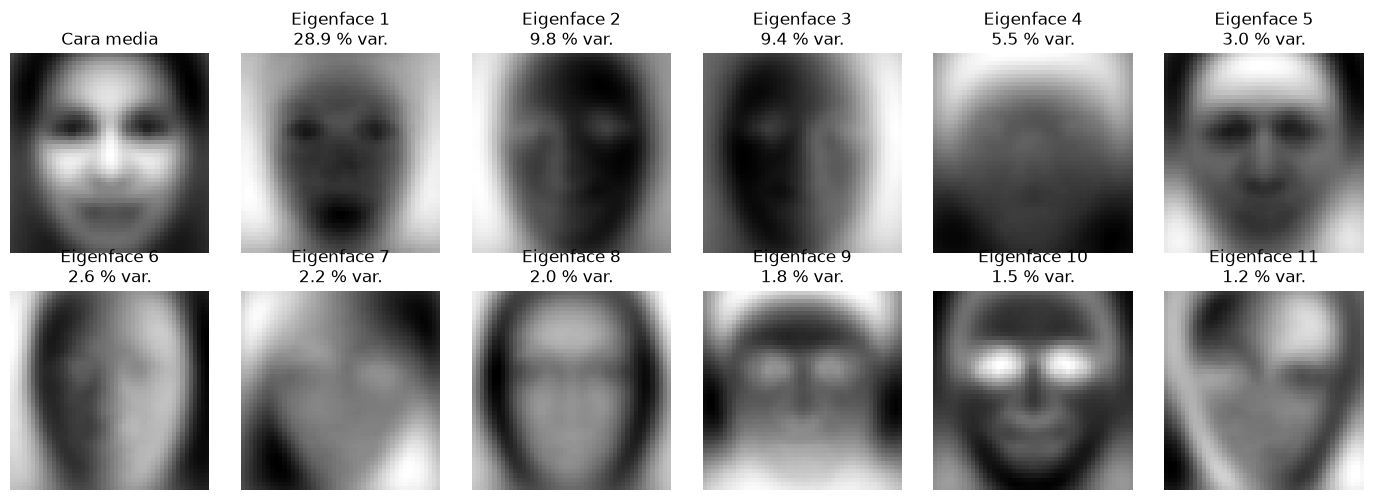

In [22]:
# ===== 3.1.2 Cara media y primeras eigenfaces del modelo final =====
n_mostrar = 11
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
axes = axes.ravel()
axes[0].imshow(pca_final.mean_.reshape(H_CARA, W_CARA), cmap="gray")
axes[0].set_title("Cara media")
for i in range(n_mostrar):
    axes[i + 1].imshow(pca_final.components_[i].reshape(H_CARA, W_CARA), cmap="gray")
    axes[i + 1].set_title(f"Eigenface {i + 1}\n{100 * pca_final.explained_variance_ratio_[i]:.1f} % var.")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 3.2 Evaluación en test y comparación con YOLO11s-cls

Ambos clasificadores se evalúan sobre las mismas 7.178 imágenes de `dataset_emociones/test`, que ninguno ha visto al entrenar. Se usan las mismas métricas (media *macro*: todas las clases pesan igual) para que la comparación sea justa. El tiempo por imagen es orientativo: el SVM corre en CPU y YOLO en GPU (si hay).

In [23]:
# ===== 3.2.1 Predicciones de ambos modelos sobre test =====
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"       # evita el error de OpenMP duplicado en Windows
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from ultralytics import YOLO

Xte, Yte, _, _, _, clases_te, w_te, h_te = LoadDataset(TEST_DIR, '.jpg')
assert list(clases_te) == CLASES, f"Las clases de test {clases_te} no coinciden con las de train {CLASES}"
Xte, Yte = np.array(Xte, dtype='float32'), np.array(Yte, dtype=int)
print(f"Test: {Xte.shape[0]} imágenes")

# --- Eigenfaces + SVM ---
t0 = time()
y_eig = modelo.predict(Xte).astype(int)
ms_eig = 1000 * (time() - t0) / len(Xte)

# --- YOLO11s-cls --- (se le pasan las mismas imágenes, en BGR como las leería de disco)
classifier = YOLO(Path("runs/classify/yolo11s-cls_emotion_detector/weights/best.pt"))
nombre_a_idx = {n: i for i, n in enumerate(CLASES)}
y_yolo = []
t0 = time()
for i in range(0, len(Xte), 256):
    lote = [cv2.cvtColor(x.reshape(h_te, w_te).astype(np.uint8), cv2.COLOR_GRAY2BGR) for x in Xte[i:i + 256]]
    for r in classifier(lote, imgsz=48, verbose=False):
        y_yolo.append(nombre_a_idx[r.names[r.probs.top1]])
y_yolo = np.array(y_yolo)
ms_yolo = 1000 * (time() - t0) / len(Xte)

print("\nEigenfaces + SVM")
print(classification_report(Yte, y_eig, target_names=CLASES))
print("YOLO11s-cls")
print(classification_report(Yte, y_yolo, target_names=CLASES))

Test: 7178 imágenes
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, upd

,Eigenfaces + SVM,YOLO11s-cls
Accuracy,0.333,0.688
Precisión (macro),0.308,0.687
Recall (macro),0.352,0.664
F1 (macro),0.301,0.672
ms / imagen,7.601,0.533


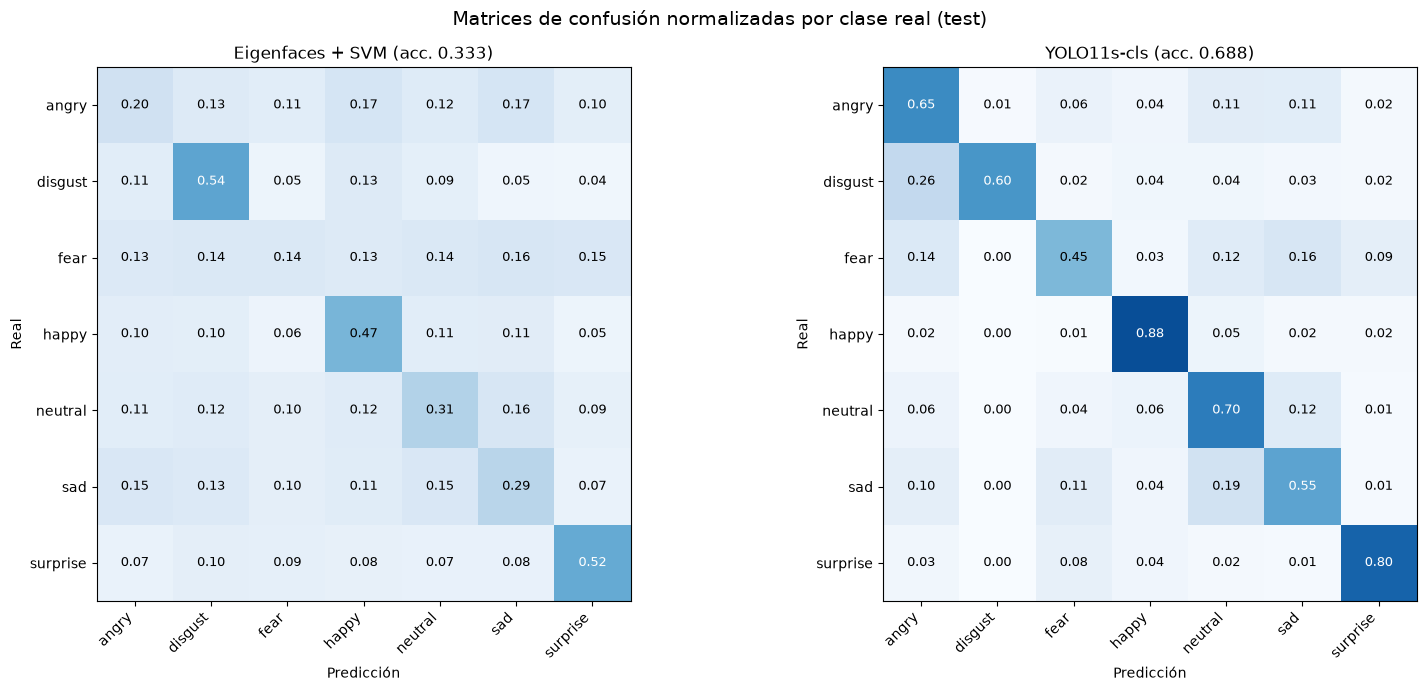

In [26]:
# ===== 3.2.2 Tabla comparativa y matrices de confusión =====
def metricas(y_true, y_pred, ms):
    return [accuracy_score(y_true, y_pred),
            precision_score(y_true, y_pred, average='macro'),
            recall_score(y_true, y_pred, average='macro'),
            f1_score(y_true, y_pred, average='macro'),
            ms]

comparacion = pd.DataFrame(
    {"Eigenfaces + SVM": metricas(Yte, y_eig, ms_eig), "YOLO11s-cls": metricas(Yte, y_yolo, ms_yolo)},
    index=["Accuracy", "Precisión (macro)", "Recall (macro)", "F1 (macro)", "ms / imagen"],
).round(3)
display(comparacion)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (titulo, y_pred) in zip(axes, [("Eigenfaces + SVM", y_eig), ("YOLO11s-cls", y_yolo)]):
    cm = confusion_matrix(Yte, y_pred, labels=range(len(CLASES)), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(len(CLASES)), CLASES, rotation=45, ha="right")
    ax.set_yticks(range(len(CLASES)), CLASES)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
    ax.set_title(f"{titulo} (acc. {accuracy_score(Yte, y_pred):.3f})")
fig.suptitle("Matrices de confusión normalizadas por clase real (test)", fontsize=14)
plt.tight_layout()
plt.show()

## Fase 4. Demo en tiempo real: YOLO11s (caras) + eigenfaces/SVM (emoción)

Misma demo que en `emotion_detector.ipynb` (hámsters, emotes de manos y cara con MediaPipe), cambiando el clasificador de emociones:

1. **YOLO11s** (`runs/detect/yolo11s_face_detector`) localiza la cara.
2. Se toma un **recorte cuadrado** centrado en la caja, se pasa a gris y se reescala a 48x48, igual que las imágenes de FER2013.
3. El recorte se proyecta sobre las **eigenfaces** y lo clasifica el **SVM**.
4. La emoción se **suaviza** con una votación de los últimos frames.

Eigenfaces compara píxel a píxel, así que es muy sensible al encuadre: con `DEBUG = True` se muestra en la esquina el recorte de 48x48 que recibe el modelo, para compararlo con las imágenes del dataset y ajustar `MARGEN` si hace falta.

### 4.1 Configuración previa

In [ ]:
# ===== 4.1.1 Imports e funciones auxiliares =====
# Hámsters, gestos de mano, gestos faciales, cámara y dibujo. Al final se añaden las funciones
# propias de este cuaderno: recorte de la cara y preprocesado para eigenfaces.
import os
import random
from collections import Counter, deque
from pathlib import Path
import joblib
import cv2
import numpy as np

from utils import *

MODELO_PATH = Path("models/eigenfaces_svm.joblib")
guardado = joblib.load(MODELO_PATH)
modelo = guardado["modelo"]
CLASES = guardado["clases"]
W_CARA, H_CARA = guardado["width"], guardado["height"]

# ---------------------------------------------------------------- Propio de eigenfaces
MARGEN = 0.0          # Margen extra alrededor de la caja de YOLO (0.1 = 10 % más grande). Ajustar si
                      # los recortes salen más o menos ajustados que las caras de FER2013
VENTANA_EMOCION = 8   # Nº de frames para la votación de la emoción (evita que cambie en cada frame)


def recorte_cuadrado(img, x1, y1, x2, y2, margen=MARGEN):
    """Caja cuadrada centrada en la detección de YOLO. Las imágenes de FER2013 son cuadradas: si se
    redimensionara la caja tal cual a 48x48 la cara quedaría deformada."""
    h_img, w_img = img.shape[:2]
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    lado = max(x2 - x1, y2 - y1) * (1 + margen)
    a1, b1 = int(max(cx - lado / 2, 0)), int(max(cy - lado / 2, 0))
    a2, b2 = int(min(cx + lado / 2, w_img)), int(min(cy + lado / 2, h_img))
    return img[b1:b2, a1:a2]


def preprocesar_cara(cara_bgr, width, height):
    """Mismo preprocesado que en el entrenamiento: gris, tamaño de FER2013 y vector fila de float32."""
    gris = cv2.cvtColor(cara_bgr, cv2.COLOR_BGR2GRAY)
    gris = cv2.resize(gris, (width, height), interpolation=cv2.INTER_AREA)
    return gris, gris.reshape(1, -1).astype(np.float32)


class VotoMayoria:
    """Emoción más repetida en los últimos n frames (a diferencia de Suavizador, siempre devuelve una)."""
    def __init__(self, n=VENTANA_EMOCION):
        self.hist = deque(maxlen=n)

    def __call__(self, valor):
        self.hist.append(valor)
        return Counter(self.hist).most_common(1)[0][0]

In [ ]:
# ===== 4.1.2 Carga del detector YOLO11s y de MediaPipe =====
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"       # evita el error de OpenMP duplicado en Windows
import time as time_mod                            # 'time' ya es la función time() importada al principio
import mediapipe as mp
from ultralytics import YOLO

detector = YOLO(Path("runs/detect/yolo11s_face_detector/weights/best.pt"))

BaseOptions = mp.tasks.BaseOptions
VisionRunningMode = mp.tasks.vision.RunningMode

HandLandmarker = mp.tasks.vision.HandLandmarker
options_hand = mp.tasks.vision.HandLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="models/hand_landmarker.task"),
    running_mode=VisionRunningMode.VIDEO,
    num_hands=2,
)

FaceLandmarker = mp.tasks.vision.FaceLandmarker
options_face = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="models/face_landmarker.task"),
    running_mode=VisionRunningMode.VIDEO,
    num_faces=1,
    output_face_blendshapes=True,
)

### 4.2 Demo en tiempo real con webcam
Al igual que el otro, se pueden usar botones para:
- Si se pulsa la `e` se muestra/oculta la imagen del hamster
- Si se pulsa la `r` se muestra/oculta los landmarks del Mediapipe
- Pulsa `ESC` para salir

In [ ]:
# ===== D.3 Prueba de vídeo en tiempo real (emotes + emociones con eigenfaces) =====
# Por cada frame: YOLO detecta la cara; si se reconoce un emote (manos o cara) se pega su hámster;
# si no, se usa la emoción que predice eigenfaces + SVM sobre el recorte de la cara.
DEBUG = True        # Estado inicial de los landmarks y el recorte (se puede cambiar en vivo con la "r")
CAMARA = 1          # Índice preferido de la webcam (si no da imagen se prueban los demás)

hamsters = cargar_hamsters(CLASES + EMOTES)

vid = cv2.VideoCapture(0)
suavizar = Suavizador()
votar_emocion = VotoMayoria()
etiqueta_actual, hamster_actual = None, None
ts_prev = -1
mostrar_hamster = True      # Tecla "e"
mostrar_landmarks = DEBUG   # Tecla "r"

with HandLandmarker.create_from_options(options_hand) as landmarker_hand, \
     FaceLandmarker.create_from_options(options_face) as landmarker_face:
    while True:
        ret, img = vid.read()
        if not ret:
            print("No se ha podido leer un frame de la cámara")
            break
        h_img, w_img = img.shape[:2]

        # Detección de caras, se elige la primera cara detectada
        faces = detector(img, verbose=False)[0]
        if len(faces.boxes) > 0:
            x1, y1, x2, y2 = faces.boxes.xyxy[0].int().tolist()
            x1, y1 = max(x1, 0), max(y1, 0)
            x2, y2 = min(x2, w_img), min(y2, h_img)
            cara = recorte_cuadrado(img, x1, y1, x2, y2)

            if cara.size > 0:
                # --- 1) Emotes: MediaPipe sobre el frame ORIGINAL (antes de pegar el hámster) ---
                ts = max(int(time_mod.time() * 1000), ts_prev + 1)    # El modo VIDEO exige timestamps crecientes
                ts_prev = ts
                mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
                res_manos = landmarker_hand.detect_for_video(mp_image, ts)
                res_cara = landmarker_face.detect_for_video(mp_image, ts)

                manos = [mano_a_pixeles(m, w_img, h_img) for m in res_manos.hand_landmarks]
                blend = blendshapes_dict(res_cara)
                emote = suavizar(elegir_emote(emotes_manos(manos, (x1, y1, x2, y2)) | emotes_cara(blend)))

                # --- 2) Emoción con eigenfaces + SVM (se calcula siempre para que la votación no se corte) ---
                cara48, vector = preprocesar_cara(cara, W_CARA, H_CARA)
                emocion = votar_emocion(CLASES[int(modelo.predict(vector)[0])])

                if emote is not None:
                    etiqueta, texto = emote, f"emote: {emote}"
                else:
                    etiqueta, texto = emocion, f"{emocion} (eigenfaces)"

                # Solo se elige un hámster aleatorio nuevo cuando cambia la etiqueta (evita parpadeo)
                if etiqueta != etiqueta_actual:
                    etiqueta_actual = etiqueta
                    hamster_actual = random.choice(hamsters[etiqueta]) if hamsters.get(etiqueta) else None

                if mostrar_hamster and hamster_actual is not None:
                    pegar_imagen(img, hamster_actual, x1, y1, x2, y2)
                color = (255, 0, 255) if emote else (0, 255, 0)     # Magenta = emote, verde = emoción
                cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
                dibujar_texto(img, texto, (x1, max(y1 - 10, 15)), color)

                if mostrar_landmarks:
                    dibujar_cara(img, res_cara, w_img, h_img)
                    for p in manos:
                        dibujar_mano(img, p)
                    dibujar_texto(img, f"mouthPucker {blend.get('mouthPucker', 0):.2f}", (10, 25), (255, 255, 0))
                    # Recorte que recibe el modelo, ampliado x3 en la esquina superior derecha
                    lado = 3 * W_CARA
                    if w_img >= lado and h_img >= lado:
                        img[0:lado, w_img - lado:w_img] = cv2.cvtColor(
                            cv2.resize(cara48, (lado, lado), interpolation=cv2.INTER_NEAREST), cv2.COLOR_GRAY2BGR)

        dibujar_texto(img, f"[e] hamster: {'ON' if mostrar_hamster else 'OFF'}   "
                           f"[r] landmarks: {'ON' if mostrar_landmarks else 'OFF'}",
                      (10, h_img - 15), (255, 255, 255), 0.5)
        cv2.imshow("Emociones: YOLO11s + eigenfaces/SVM", img)
        tecla = cv2.waitKey(1) & 0xFF
        if tecla == 27:  # Esc para salir
            break
        elif tecla in (ord("e"), ord("E")):
            mostrar_hamster = not mostrar_hamster
        elif tecla in (ord("r"), ord("R")):
            mostrar_landmarks = not mostrar_landmarks

vid.release()
cv2.destroyAllWindows()

Cámara abierta: índice 1
